# Evaluating the impact of hyperparameter estimation on performance

In this notebook, we compare a spatiostatic simulation with an exponentially weighted coverage metric. The first run contains a simulation where hyperparameters are known. The second run contains a simulation where hyperparameters are estimated based on the measurements collected. 

In [1]:
import Pkg; Pkg.activate("../.."); Pkg.instantiate()

  Activating project at `~/Documents/adaptive-ocean-exploration-sim`


In [2]:
using Logging: global_logger
using TerminalLoggers: TerminalLogger
global_logger(TerminalLogger())

using ProgressLogging

In [3]:
using Plots, Revise, StaticArrays, Interpolations, LinearAlgebra

In [4]:
include("../../src/kf.jl")
include("../../src/ngpkf.jl")
include("../../src/SyntheticData.jl")
include("../../src/variograms.jl")
include("../../src/ergodic.jl")
include("../../src/SOC_Controller.jl")
include("../../src/simulator_spatial.jl")

Main.SimulatorSpatial

## Spatial-only Matern-12 Kernel - Synthetic Data

In [5]:
# Define domain vars
dim = 100; # number of data points along each axis in the domain (defining a square domain)
xstart, xstop = 0, 25; # x-axis start and end positions
ystart, ystop = 0, 10; # y-axis start and end positions

σ_sq = 1.0
λₓ = 1/(5.0) 

env_data = SyntheticData.matern12_spatial(dim, xstart, xstop, ystart, ystop, σ_sq, λₓ);
# heatmap(range(xstart, stop=xstop, length=dim), range(ystart, stop=ystop, length=dim), env_data; c = :vik)
# title!("Synthetic Data: σ² = $(σ_sq), λₓ = $(λₓ)")

Main.SyntheticData.EnvDataSpatial{Vector{Float64}, Matrix{Float64}, Interpolations.Extrapolation{Float64, 2, Interpolations.GriddedInterpolation{Float64, 2, Matrix{Float64}, Gridded{Linear{Throw{OnGrid}}}, Tuple{Vector{Float64}, Vector{Float64}}}, Gridded{Linear{Throw{OnGrid}}}, Throw{Nothing}}}([0.0, 0.25252525252525254, 0.5050505050505051, 0.7575757575757576, 1.0101010101010102, 1.2626262626262625, 1.5151515151515151, 1.7676767676767677, 2.0202020202020203, 2.272727272727273  …  22.727272727272727, 22.97979797979798, 23.232323232323232, 23.484848484848484, 23.737373737373737, 23.98989898989899, 24.242424242424242, 24.494949494949495, 24.747474747474747, 25.0], [0.0, 0.10101010101010101, 0.20202020202020202, 0.30303030303030304, 0.40404040404040403, 0.5050505050505051, 0.6060606060606061, 0.7070707070707071, 0.8080808080808081, 0.9090909090909091  …  9.090909090909092, 9.191919191919192, 9.292929292929292, 9.393939393939394, 9.494949494949495, 9.595959595959595, 9.696969696969697, 9.7

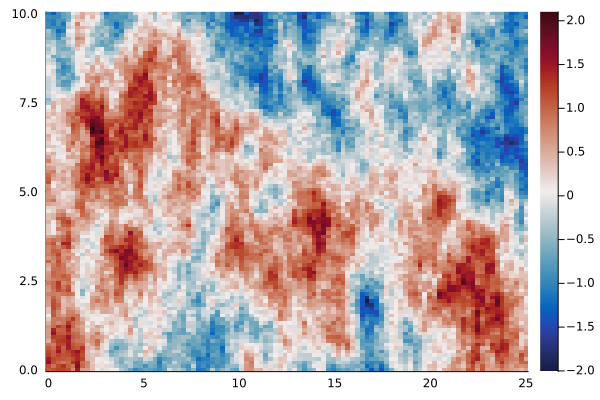

In [6]:
# plotly();
heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx)
# plot!(clims=(-2,2))

In [7]:
# Create an ngpkf grid based on the data

σ_spatial = σ_sq
# l_spatial = 1/λₓ_wrong
l_spatial = 1/λₓ

res_factor = 0.4 #l_spatial / sqrt(2.0)

kern = NGPKF.MaternKernel(σ_spatial, l_spatial)

ngp_grid_x = range(extrema(env_data.X)..., step= res_factor )
ngp_grid_y = range(extrema(env_data.Y)..., step= res_factor )


0.0:0.4:10.0

In [8]:
ngpkf_grid = NGPKF.NGPKFGrid(ngp_grid_x, ngp_grid_y, kern)

Main.NGPKF.NGPKFGrid{StepRangeLen{Float64, Base.TwicePrecision{Float64}, Base.TwicePrecision{Float64}, Int64}, Vector{SVector{2, Float64}}, Hermitian{Float64, Matrix{Float64}}, Main.NGPKF.MaternKernel{Float64}}(0.0:0.4:24.8, 0.0:0.4:10.0, SVector{2, Float64}[[0.0, 0.0], [0.4, 0.0], [0.8, 0.0], [1.2, 0.0], [1.6, 0.0], [2.0, 0.0], [2.4, 0.0], [2.8, 0.0], [3.2, 0.0], [3.6, 0.0]  …  [21.2, 10.0], [21.6, 10.0], [22.0, 10.0], [22.4, 10.0], [22.8, 10.0], [23.2, 10.0], [23.6, 10.0], [24.0, 10.0], [24.4, 10.0], [24.8, 10.0]], Main.NGPKF.MaternKernel{Float64}(1.0, 5.0), [10.221468408218866 -5.359611588172399 … 8.996671571816947e-7 3.2167883957520634e-6; -5.359611588172399 14.078370726036605 … 1.9874550562190964e-7 8.996671570065702e-7; … ; 8.996671571816947e-7 1.9874550562190964e-7 … 14.07837072603662 -5.359611588172376; 3.2167883957520634e-6 8.996671570065702e-7 … -5.359611588172376 10.22146840821884])

In [9]:
size(ngp_grid_x), size(ngp_grid_y)

((63,), (26,))

In [10]:
x0s = [@SVector[rand(ngpkf_grid.xs[2:(end-2)]), rand(ngpkf_grid.ys[2:(end-2)])] for i=1:1]


1-element Vector{SVector{2, Float64}}:
 [22.0, 5.6]

In [11]:
SimulatorSpatial.measure(0.0, x0s, env_data; σ_meas = 0.05)

1-element Vector{Main.SimulatorSpatial.MeasurementSpatial{Float64, SVector{2, Float64}, Float64}}:
 Main.SimulatorSpatial.MeasurementSpatial{Float64, SVector{2, Float64}, Float64}(0.0, [22.0, 5.6], -0.4589496958854484)

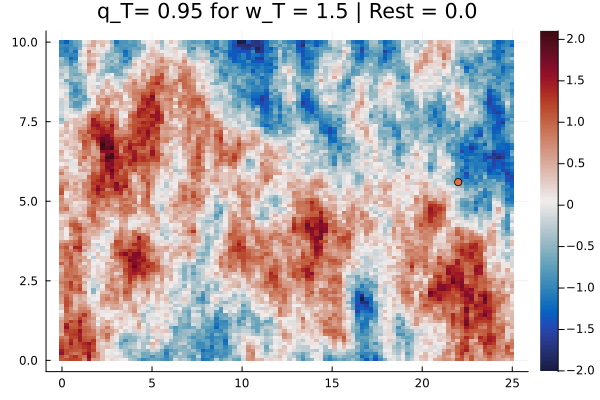

In [12]:
plot()
heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx)
scatter!(first.(x0s), last.(x0s), label = "")
title!("q_T= 0.95 for w_T = 1.5 | Rest = 0.0")
# plot!(clims=(-2,2))

# Define Time Scales & Generate SOC Target

In [13]:
# Frequencies
# Control input: Every 5 seconds
# Fusing Measurements: Every 300 seconds

ΔT = 5.0/60.0 # minutes
T_begin = 9.0; # hours
T_end = 12.0; # hours 
ts = T_begin*60:(ΔT):T_end*60
fuse_measurements_every_ΔT = 5.0 # minutes
recompute_controller_every_ΔT = 5.0 / 60.0 # minutes
σ_t = zeros(63, 26);

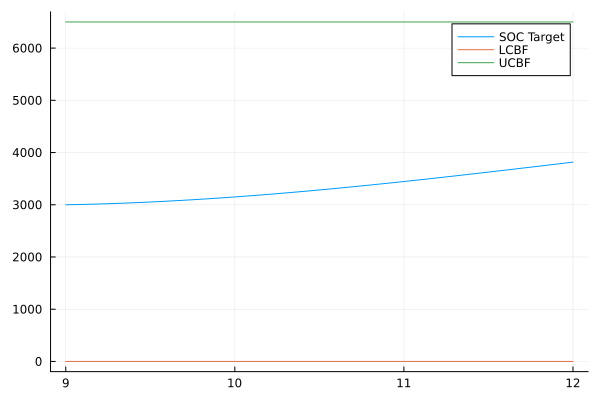

In [14]:
# Generate SOC_Target Profile
soc_begin = 3000
soc_end = 3500
lcbf = SoCController.compute_lcbf(ts/60, ΔT/60);
ucbf = SoCController.compute_ucbf(ts/60, ΔT/60);
soc_target = SoCController.generate_SOC_target(lcbf, ucbf,  soc_begin, soc_end, ts/60, ΔT/60);
plot(ts/60, soc_target, label="SOC Target")
plot!(ts/60, lcbf, label="LCBF")
plot!(ts/60,ucbf, label="UCBF")

## Define Clarity Computation Methods & Controller

In [15]:
function Cfun(p, x)
    return kern(x, p)^2 / kern(p, p)
end
function Rfun(p, x)
    return (kern(x,x) - kern(x, p)^2 / kern(p, p) + 0.5^2)/(ΔT)
end


S(p, x)  = Cfun(p, x)^2 / Rfun(p, x)
DxS(p, x) = ForwardDiff.gradient(xx-> S(p, xx), x)

DxS (generic function with 1 method)

In [16]:
using DifferentialEquations
using ForwardDiff

function clarity_prediction(t, q0, C, R, Q)

    k = C / sqrt(Q * R)
    
    q∞ = k / (1 + k)

    γ1 = q∞ - q0
    γ2 = γ1 * (k-1)
    γ3 = (k-1) * q0 - k

    return q∞ * ( 1 + 2 * γ1 / (γ2 + γ3 * exp(2 * k * Q * t)))
end

    
function clarity_time(q0, qf, C, R, Q; tmax=10.0)
    
    println("q0: $(q0)")
    println("qf: $(qf)")
    println("C: $(C)")
    println("R: $(R)")
    println("Q: $(Q)")
    
    if q0 >= qf
        return 0.0
    end

    k = C / sqrt(Q * R)
    println("k: $(k)")
    
    q∞ = k / (1 + k)
    println("q∞: $(q∞)")
    γ1 = q∞ - q0
    γ2 = γ1 * (k-1)
    γ3 = (k-1) * q0 - k

    
        
    if qf >= q∞
        return tmax
    end

    t = log((2*q∞*γ1 - qf*γ2 + q∞*γ2)/((qf - q∞)*γ3))/(2*k*Q)
    println("t: $(t)")

    return min(t, tmax)
end


C_ = Cfun(0,0)
R_ = Rfun(0,0)

k = (C_^2 / R_)
# q(t) = ((-k * t * q_0) + (k * t * q_0)) / ((-k * t * q_0) + (k * t) + 1)

function Clarity_delta_t(current_clarity, target_clarity)
    delta_t = (target_clarity - current_clarity) / ((target_clarity - 1) * k * (current_clarity - 1))
    return delta_t
end

function Clarity_delta_new(current_clarity, target_clarity)
    den = -target_clarity*k + k*current_clarity*target_clarity + k - k*current_clarity
    return delta_t = (target_clarity - current_clarity) / den
end


Clarity_delta_new (generic function with 1 method)

In [17]:
# Controller for weighted 2
using LinearAlgebra, StatsBase

function ergo_controller_weighted_2(t, xs, Mean, w_rated_val;
        ergo_grid,
        ergo_q_map,
        traj,
        umax=30.0 * 60 / 1000,
        ΔT,
        kwargs...
        )
        
    target_q = 0.95

    # Set the rated value matrix    
    Nx, Ny = length(ngpkf_grid.xs), length(ngpkf_grid.ys)
    w_rated = ones(Nx, Ny)
    w_rated *= w_rated_val
  
#   Compute the target matrix 
    lambda_param = 0.1
    delta = -lambda_param*((Mean - w_rated).^2)
    q_target_temp = target_q*(exp.(delta))    

    # Get it in the right shape
    q_target_itp = linear_interpolation((ngpkf_grid.xs, ngpkf_grid.ys), q_target_temp, extrapolation_bc=Line())
    q_target_weighted = q_target_itp(ErgodicController.xs(ergo_grid), ErgodicController.ys(ergo_grid))     

    
    target_spatial_dist = zeros(size(ergo_q_map))
    Qp  = mean(σ_t.^2) # diagm(vec(σ_t .^2 * fuse_measurements_every_ΔT ))      
    
    for i in CartesianIndices(target_spatial_dist)
        if q_target_weighted[i] > ergo_q_map[i]
#             println("here in first cond")
            target_spatial_dist[i] = Clarity_delta_new(ergo_q_map[i], q_target_weighted[i])
        else
            target_spatial_dist[i] = 0.0
        end
    end
        
    u = [ErgodicController.controller_single_integrator(ergo_grid, x, traj, target_spatial_dist; umax=umax) for x in xs]
    
#     println(u)
    
    return u, q_target_temp

end

ergo_controllers_weighted_2 = [ergo_controller_weighted_2 for i=1:length(x0s)]

1-element Vector{typeof(ergo_controller_weighted_2)}:
 ergo_controller_weighted_2 (generic function with 1 method)

# Simulations with known hyperparameters

In [18]:
w_rated_val = 1.0

@time res_ergo_exp =  SimulatorSpatial.simulate_weighted_exp_SoC_spatial(ts, x0s, soc_begin, ergo_controller_weighted_2, soc_target, w_rated_val; 
    ngpkf_grid=ngpkf_grid, 
    EnvDataSpatial=env_data, 
    σ_meas = 0.5,
    # σ_process= 0.075 * fuse_measurements_every_ΔT,
    Q_process = diagm(vec(σ_t .^2 * fuse_measurements_every_ΔT )) , 
    fuse_measurements_every_ΔT = fuse_measurements_every_ΔT, 
    recompute_controller_every_ΔT = recompute_controller_every_ΔT)

Progress:   0%|                                         |  ETA: N/A
Progress:   1%|▎                                        |  ETA: 0:07:28
Progress:   1%|▍                                        |  ETA: 0:04:44
Progress:   2%|▋                                        |  ETA: 0:03:34
Progress:   2%|▉                                        |  ETA: 0:02:59
Progress:   3%|█                                        |  ETA: 0:02:43


Inside prediction of NGP


Progress:   3%|█▎                                       |  ETA: 0:03:46
Progress:   4%|█▌                                       |  ETA: 0:03:23
Progress:   4%|█▋                                       |  ETA: 0:03:10
Progress:   5%|█▉                                       |  ETA: 0:03:00
Progress:   5%|██▏                                      |  ETA: 0:02:51


Inside prediction of NGP


Progress:   6%|██▎                                      |  ETA: 0:02:54
Progress:   6%|██▌                                      |  ETA: 0:02:46
Progress:   7%|██▊                                      |  ETA: 0:02:38
Progress:   7%|██▉                                      |  ETA: 0:02:33
Progress:   8%|███▏                                     |  ETA: 0:02:30
Progress:   8%|███▍                                     |  ETA: 0:02:25


...

Inside prediction of NGP


Progress:  97%|███████████████████████████████████████▉ |  ETA: 0:00:03
Progress:  98%|████████████████████████████████████████▏|  ETA: 0:00:02
Progress:  98%|████████████████████████████████████████▎|  ETA: 0:00:02
Progress:  99%|████████████████████████████████████████▌|  ETA: 0:00:01
Progress:  99%|████████████████████████████████████████▊|  ETA: 0:00:01
Progress: 100%|████████████████████████████████████████▉|  ETA: 0:00:00


109.390896 seconds (1.92 G allocations: 53.085 GiB, 8.92% gc time, 7.50% compilation time)


Progress: 100%|█████████████████████████████████████████| Time: 0:01:44


Main.SimulatorSpatial.SimResultWeightedSpeed{StepRangeLen{Float64, Base.TwicePrecision{Float64}, Base.TwicePrecision{Float64}, Int64}, Vector{Vector{SVector{2, Float64}}}, Vector{Vector{SVector{2, Float64}}}, Vector{Float64}, Vector{Main.SimulatorSpatial.MeasurementSpatial{Float64, SVector{2, Float64}, Float64}}, Vector{Float64}, Vector{Main.KF.KFState{Vector{Float64}, UpperTriangular{Float64, Matrix{Float64}}}}, Vector{Matrix{Float64}}}(540.0:0.08333333333333333:720.0, Vector{SVector{2, Float64}}[[[22.0, 5.6]], [[21.98322477617445, 5.674193889125366]], [[21.93472774602213, 5.77078814868659]], [[21.869446988483627, 5.875797721006408]], [[21.78870874905995, 5.9894337452499355]], [[21.695799914569754, 6.1033649628546165]], [[21.592560849236495, 6.217365316178673]], [[21.482176410403756, 6.328883946874687]], [[21.365884313134263, 6.438998170016873]], [[21.24757232263001, 6.548504903145056]]  …  [[16.980525907752828, 3.3851127859809993]], [[16.832058490525043, 3.407310218566965]], [[16.685

## Data Processing - Known Hyperparameters

In [19]:
res_ergo_exp.ts

540.0:0.08333333333333333:720.0

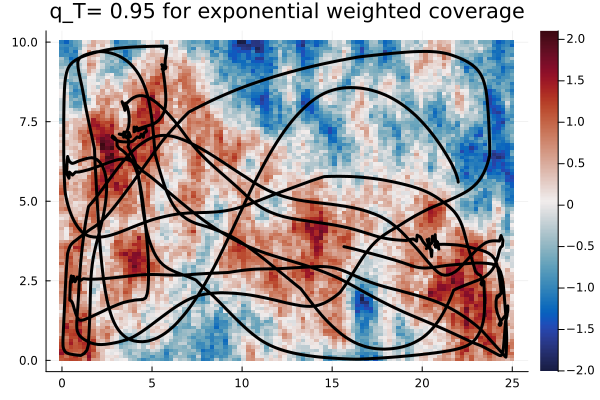

In [20]:
plot()
heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx)
for i=1:length(x0s)
    x = [r[i][1] for r in res_ergo_exp.xs]
    y = [r[i][2] for r in res_ergo_exp.xs]
    plot!(x,y, linewidth=3, color=:black, label = "")
end
plot!()

title!("q_T= 0.95 for exponential weighted coverage")

[ Info: Saved animation to /tmp/jl_qZUnmzUh8t.gif


Plots.AnimatedGif("/tmp/jl_qZUnmzUh8t.gif")
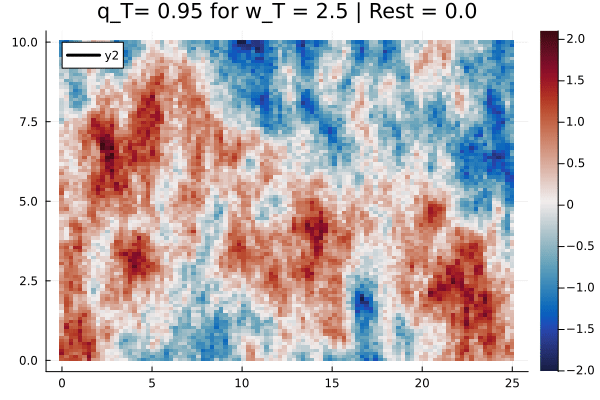

In [21]:
gr()
@gif for n = Int.(floor.(range(1, length(res_ergo_exp.xs), length=420)))
    plot()
    heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx)
    for i=1:length(x0s)
        x = [r[i][1] for r in res_ergo_exp.xs[1:n]]
        y = [r[i][2] for r in res_ergo_exp.xs[1:n]]
        plot!(x, y, linewidth=3, color=:black)
    end
    plot!()
    title!("q_T= 0.95 for w_T = 2.5 | Rest = 0.0")
end

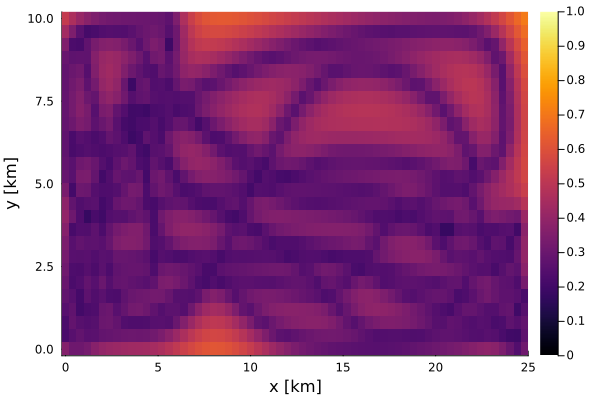

In [22]:
p2 = heatmap(ngpkf_grid, res_ergo_exp.w_hats[end], clims=(0, 1.0), plotstd=true)
# for i=1:length(x0s)
#     x = [r[i][1] for r in res_ergo.xs]
#     y = [r[i][2] for r in res_ergo.xs]
#     plot!(x, y, linewidth=3)
# end
plot!()

In [23]:
target_maps_exp = [res_ergo_exp.q_target_maps[1],]

for i=2:63:length(res_ergo_exp.q_target_maps)
    push!(target_maps_exp,res_ergo_exp.q_target_maps[i])
end

[ Info: Saved animation to /tmp/jl_kFSf2vu7Gd.gif


Plots.AnimatedGif("/tmp/jl_kFSf2vu7Gd.gif")
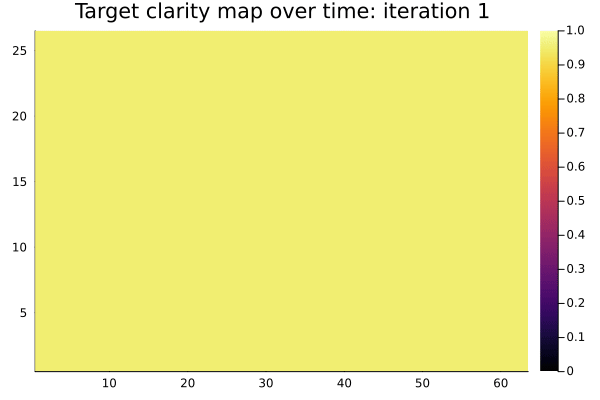

In [24]:
gr()
@gif for i=1:length(res_ergo_exp.q_target_maps)
    heatmap(res_ergo_exp.q_target_maps[i]', clims=(0, 1))
    title!("Target clarity map over time: iteration $i")
end

[ Info: Saved animation to /tmp/jl_63M5k1uLqj.gif


Plots.AnimatedGif("/tmp/jl_63M5k1uLqj.gif")
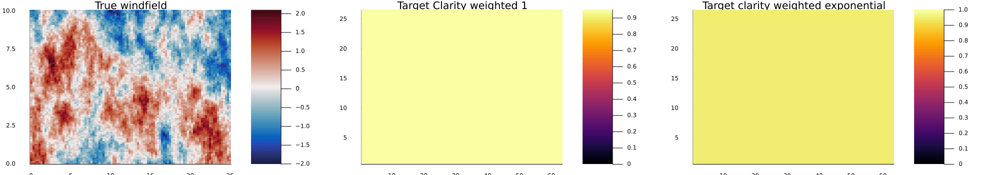

In [25]:
# Comparing two target clarities
gr()
@gif for i=1:length(res_ergo_exp.q_target_maps)
    p0 = heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx, title = "True windfield")
    p1 = heatmap(res_ergo_exp.q_target_maps[i]', title = "Target Clarity weighted 1")
    p2 = heatmap(res_ergo_exp.q_target_maps[i]', clims=(0, 1), title = "Target clarity weighted exponential")
    plot(p0, p1, p2, layout=@layout[a b c], size=(2000, 350))
#     title!("Weighted coverage")
end

[ Info: Saved animation to /tmp/jl_S7o7MlIzGZ.gif


Plots.AnimatedGif("/tmp/jl_S7o7MlIzGZ.gif")
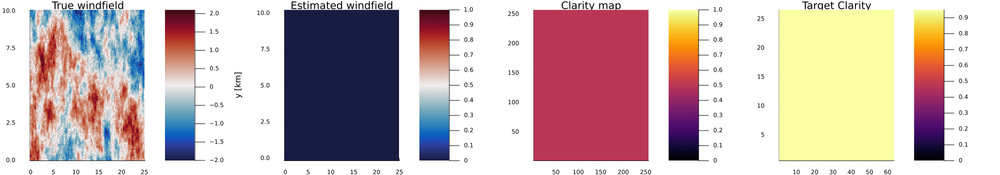

In [26]:
gr()
@gif for i=1:length(res_ergo_exp.ergo_q_maps)
    p0 = heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx, title = "True windfield")
    p1 = heatmap(ngpkf_grid, res_ergo_exp.w_hats[i],colormap=:balance, title = "Estimated windfield")
    p3 = heatmap(target_maps_exp[i]', title = "Target Clarity")
    p2 = heatmap(res_ergo_exp.ergo_q_maps[i]', clims=(0, 1), title = "Clarity map")
    plot(p0, p1, p2, p3, layout=@layout[a b c d], size=(2000, 350))
#     title!("Weighted coverage")
end

[ Info: Saved animation to /tmp/jl_k1W9CD8hIf.gif


Plots.AnimatedGif("/tmp/jl_k1W9CD8hIf.gif")
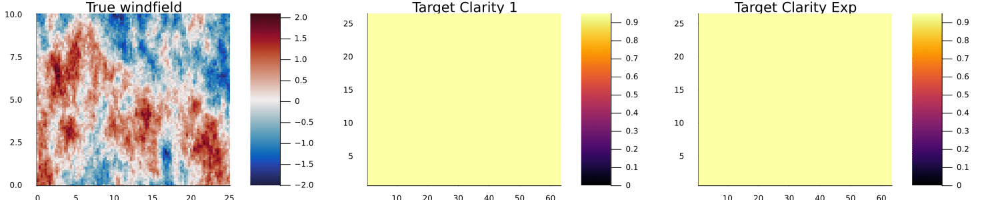

In [27]:
gr()
@gif for i=1:length(res_ergo_exp.ergo_q_maps)
    p0 = heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx, title = "True windfield")
    p1 = heatmap(target_maps_exp[i]', title = "Target Clarity 1")
    p2 = heatmap(target_maps_exp[i]', title = "Target Clarity Exp")
    plot(p0, p1, p2, layout=@layout[a b c], size=(1500, 300))
#     title!("Weighted coverage")
end

[ Info: Saved animation to /tmp/jl_Y1chilS3A7.gif


Plots.AnimatedGif("/tmp/jl_Y1chilS3A7.gif")
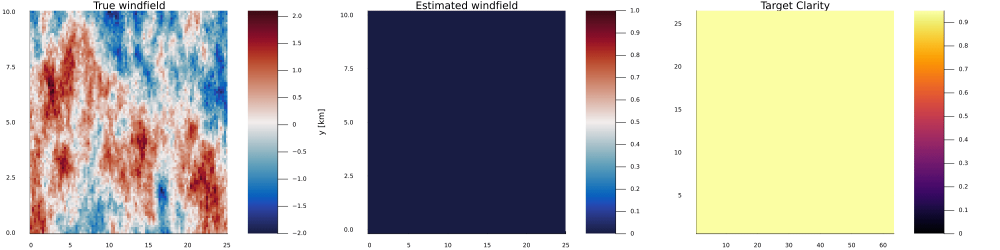

In [32]:
gr()
@gif for i=1:length(res_ergo_exp.ergo_q_maps)
    p0 = heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx, title = "True windfield")
    p1 = heatmap(ngpkf_grid, res_ergo_exp.w_hats[i],colormap=:balance, title = "Estimated windfield")
    p3 = heatmap(target_maps_exp[i]', title = "Target Clarity")
    plot(p0, p1, p3, layout=@layout[a b c], size=(2000, 500))
#     title!("Weighted coverage")
end

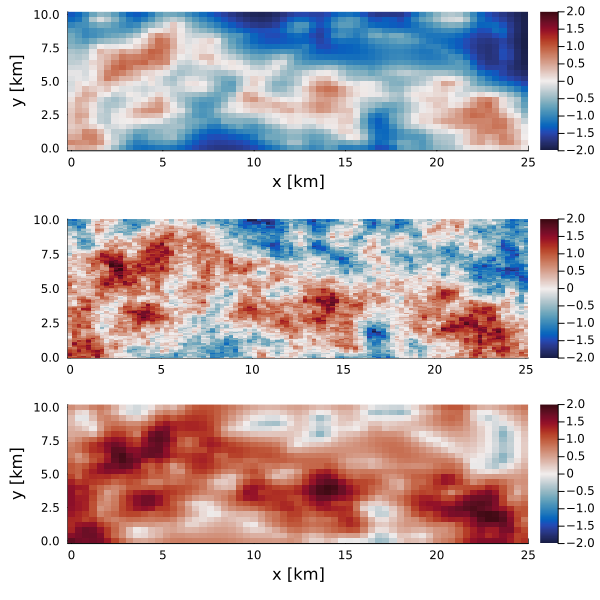

In [36]:
gr()

p1 = heatmap(ngpkf_grid, res_ergo_exp.w_hats[end],colormap=:balance, clims=(-2,2), plot_min=true)
p2 = heatmap(ngpkf_grid, res_ergo_exp.w_hats[end],colormap=:balance, clims=(-2,2), plot_max=true)
p3 = heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx, clims=(-2, 2))
    
plot(p1, p3, p2, layout = (@layout [a;b; c]), size=[600, 600])

In [37]:
# Compute RMSE

Nx, Ny = length(ngpkf_grid.xs), length(ngpkf_grid.ys)

M = reshape(KF.μ(res_ergo_exp.w_hats[end]), Nx, Ny)
heatmap(M',colormap=:balance, clims=(-2,2) )
x_new = 0:0.4:25
y_new = 0:0.4:10
Data_sampled = [env_data.itp_w(xi, yi) for yi in y_new, xi in x_new]
Diff = M' .- Data_sampled
rmse = sqrt(mean(Diff .^ 2))

0.26998889595376735

In [38]:
M'

26×63 adjoint(::Matrix{Float64}) with eltype Float64:
  1.07987      1.07813     1.0526    …   0.689537      0.643731
  1.12083      1.13731     1.16761       0.766911      0.653198
  0.892979     1.04946     1.2257        0.795177      0.555356
  0.798647     0.901795    1.07684       0.708203      0.448045
  0.766913     0.796327    0.739387      0.665338      0.385624
  0.848348     0.882199    0.751532  …   0.652195      0.389553
  0.886821     0.96761     0.904908      0.489705      0.296841
  0.881044     0.920836    0.853447      0.273368      0.149903
  0.855241     0.887963    0.822038      0.0846392     0.00547721
  0.805603     0.843242    0.86815       0.000710773  -0.109085
  ⋮                                  ⋱                
  0.223582     0.237184    0.373972     -0.906326     -0.857069
  0.161099     0.193115    0.317968     -0.905469     -0.861834
 -0.00823482   0.0257025   0.114202     -0.916816     -0.859634
 -0.0924415   -0.131469   -0.17313   …  -0.903955     -0.

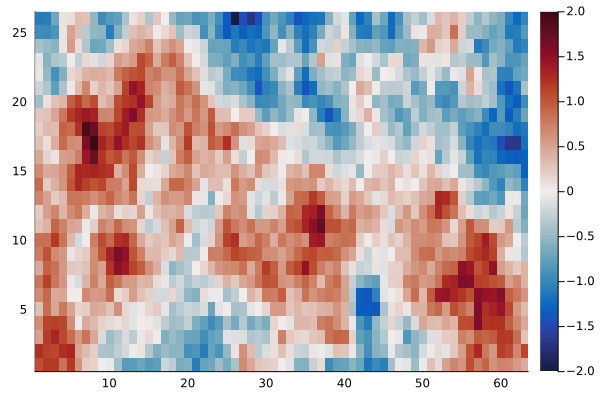

In [39]:
heatmap(Data_sampled,colormap=:balance, clims=(-2,2))

In [40]:
# Compute Precision

σ_prec = KF.σ(res_ergo_exp.w_hats[end])
M_prec = reshape(σ_prec, Nx, Ny)
precision = sum(M_prec)/length(M_prec)

0.32439868462180693

In [45]:
using LinearAlgebra, StatsBase

mean_deficit_1 = [mean(map( c -> max(0, 1.0 - c), q )) for q in res_ergo_exp.ergo_q_maps]
mean_deficit_1[end]

0.09617907169804599

In [46]:
ts = range(1, 100, 20)
time = collect(ts)

20-element Vector{Float64}:
   1.0
   6.2105263157894735
  11.421052631578947
  16.63157894736842
  21.842105263157894
  27.05263157894737
  32.26315789473684
  37.473684210526315
  42.68421052631579
  47.89473684210526
  53.10526315789474
  58.31578947368421
  63.526315789473685
  68.73684210526316
  73.94736842105263
  79.15789473684211
  84.36842105263158
  89.57894736842105
  94.78947368421052
 100.0

In [47]:
# plot(res_ergo.w_hat_ts, mean_deficit_1, marker=:dot)
gr()
plot()
plot!(time, mean_deficit_1, marker=:dot)
ylabel!("Clarity Deficit[0,1]")
xlabel!("Time [min]")
ylims!(0., 0.6)

┌ Warning: Keyword argument markerstrokestyle not supported with
│ Plots.GRBackend(). Choose from: annotationcolor, annotationfontfamily,
│ annotationfontsize, annotationhalign, annotationrotation, annotations,
│ annotationvalign, arrow, aspectratio, axis, backgroundcolor,
│ backgroundcolorinside, backgroundcoloroutside, backgroundcolorsubplot,
│ barwidth, bins, bottommargin, camera, clims, colorpalette, colorbar,
│ colorbarentry, colorbarscale, colorbartitle, colorbartitlefont,
│ colorbartitlefontcolor, colorbartitlefontrotation, colorbartitlefontsize,
│ connections, contourlabels, discretevalues, fill, fillz, fillalpha,
│ fillcolor, fillrange, fillstyle, flip, fontfamily, fontfamilysubplot,
│ foregroundcolor, foregroundcoloraxis, foregroundcolorborder,
│ foregroundcolorgrid, foregroundcolorsubplot, foregroundcolortext,
│ formatter, framestyle, grid, gridalpha, gridlinewidth, gridstyle, group,
│ guide, guidefont, guidefontcolor, guidefontfamily, guidefonthalign,
│ guidefontrotation, g

In [50]:
h2 = 25 - 1
ux_min = 1 * h2

24

### Velocity Plots

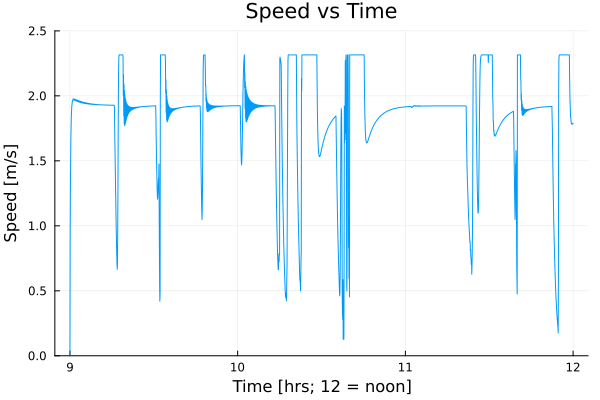

In [51]:
speed = norm.(res_ergo_exp.us)

plot(LinRange(T_begin, T_end, length(speed)), speed, legend=false)
ylims!(0., 2.5)
xlabel!("Time [hrs; 12 = noon]")
ylabel!("Speed [m/s]")
title!("Speed vs Time")

# Simulation - Hyperparameter Estimation

# Define Time Scales & Generate SOC Target

In [52]:
# Frequencies
# Control input: Every 5 seconds
# Fusing Measurements: Every 300 seconds

ΔT = 5.0/60.0 # minutes
T_begin = 9.0; # hours
T_end = 12.0; # hours 
ts = T_begin*60:(ΔT):T_end*60
fuse_measurements_every_ΔT = 5.0 # minutes
recompute_controller_every_ΔT = 5.0 / 60.0 # minutes
σ_t = zeros(63, 26);

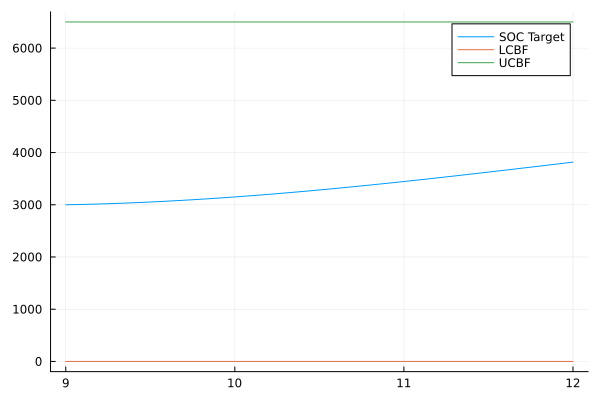

In [53]:
# Generate SOC_Target Profile
soc_begin = 3000
soc_end = 3500
lcbf = SoCController.compute_lcbf(ts/60, ΔT/60);
ucbf = SoCController.compute_ucbf(ts/60, ΔT/60);
soc_target = SoCController.generate_SOC_target(lcbf, ucbf,  soc_begin, soc_end, ts/60, ΔT/60);
plot(ts/60, soc_target, label="SOC Target")
plot!(ts/60, lcbf, label="LCBF")
plot!(ts/60,ucbf, label="UCBF")

## Define Clarity Computation Methods & Controller

In [54]:
function Cfun(p, x)
    return kern(x, p)^2 / kern(p, p)
end
function Rfun(p, x)
    return (kern(x,x) - kern(x, p)^2 / kern(p, p) + 0.5^2)/(ΔT)
end


S(p, x)  = Cfun(p, x)^2 / Rfun(p, x)
DxS(p, x) = ForwardDiff.gradient(xx-> S(p, xx), x)

DxS (generic function with 1 method)

In [55]:
using DifferentialEquations
using ForwardDiff

function clarity_prediction(t, q0, C, R, Q)

    k = C / sqrt(Q * R)
    
    q∞ = k / (1 + k)

    γ1 = q∞ - q0
    γ2 = γ1 * (k-1)
    γ3 = (k-1) * q0 - k

    return q∞ * ( 1 + 2 * γ1 / (γ2 + γ3 * exp(2 * k * Q * t)))
end

    
function clarity_time(q0, qf, C, R, Q; tmax=10.0)
    
    println("q0: $(q0)")
    println("qf: $(qf)")
    println("C: $(C)")
    println("R: $(R)")
    println("Q: $(Q)")
    
    if q0 >= qf
        return 0.0
    end

    k = C / sqrt(Q * R)
    println("k: $(k)")
    
    q∞ = k / (1 + k)
    println("q∞: $(q∞)")
    γ1 = q∞ - q0
    γ2 = γ1 * (k-1)
    γ3 = (k-1) * q0 - k

    
        
    if qf >= q∞
        return tmax
    end

    t = log((2*q∞*γ1 - qf*γ2 + q∞*γ2)/((qf - q∞)*γ3))/(2*k*Q)
    println("t: $(t)")

    return min(t, tmax)
end


C_ = Cfun(0,0)
R_ = Rfun(0,0)

k = (C_^2 / R_)
# q(t) = ((-k * t * q_0) + (k * t * q_0)) / ((-k * t * q_0) + (k * t) + 1)

function Clarity_delta_t(current_clarity, target_clarity)
    delta_t = (target_clarity - current_clarity) / ((target_clarity - 1) * k * (current_clarity - 1))
    return delta_t
end

function Clarity_delta_new(current_clarity, target_clarity)
    den = -target_clarity*k + k*current_clarity*target_clarity + k - k*current_clarity
    return delta_t = (target_clarity - current_clarity) / den
end


Clarity_delta_new (generic function with 1 method)

In [56]:
# Controller for weighted 2
using LinearAlgebra, StatsBase

function ergo_controller_weighted_2(t, xs, Mean, w_rated_val;
        ergo_grid,
        ergo_q_map,
        traj,
        umax=30.0 * 60 / 1000,
        ΔT,
        kwargs...
        )
        
    target_q = 0.95

    # Set the rated value matrix    
    Nx, Ny = length(ngpkf_grid.xs), length(ngpkf_grid.ys)
    w_rated = ones(Nx, Ny)
    w_rated *= w_rated_val
  
#   Compute the target matrix 
    lambda_param = 0.1
    delta = -lambda_param*((Mean - w_rated).^2)
    q_target_temp = target_q*(exp.(delta))    

    # Get it in the right shape
    q_target_itp = linear_interpolation((ngpkf_grid.xs, ngpkf_grid.ys), q_target_temp, extrapolation_bc=Line())
    q_target_weighted = q_target_itp(ErgodicController.xs(ergo_grid), ErgodicController.ys(ergo_grid))     

    
    target_spatial_dist = zeros(size(ergo_q_map))
    Qp  = mean(σ_t.^2) # diagm(vec(σ_t .^2 * fuse_measurements_every_ΔT ))      
    
    for i in CartesianIndices(target_spatial_dist)
        if q_target_weighted[i] > ergo_q_map[i]
#             println("here in first cond")
            target_spatial_dist[i] = Clarity_delta_new(ergo_q_map[i], q_target_weighted[i])
        else
            target_spatial_dist[i] = 0.0
        end
    end
        
    u = [ErgodicController.controller_single_integrator(ergo_grid, x, traj, target_spatial_dist; umax=umax) for x in xs]
    
#     println(u)
    
    return u, q_target_temp

end

ergo_controllers_weighted_2 = [ergo_controller_weighted_2 for i=1:length(x0s)]

1-element Vector{typeof(ergo_controller_weighted_2)}:
 ergo_controller_weighted_2 (generic function with 1 method)

In [57]:
w_rated_val = 1.0

@time res_ergo_hp =  SimulatorSpatial.simulate_weighted_exp_SoC_spatial_param(ts, x0s, soc_begin, ergo_controller_weighted_2, soc_target, w_rated_val; 
    ngpkf_grid=ngpkf_grid, 
    EnvDataSpatial=env_data, 
    σ_meas = 0.5,
    # σ_process= 0.075 * fuse_measurements_every_ΔT,
    Q_process = diagm(vec(σ_t .^2 * fuse_measurements_every_ΔT )) , 
    fuse_measurements_every_ΔT = fuse_measurements_every_ΔT, 
    recompute_controller_every_ΔT = recompute_controller_every_ΔT)

Progress:   0%|                                         |  ETA: N/A
Progress:   1%|▎                                        |  ETA: 0:01:41
Progress:   1%|▍                                        |  ETA: 0:01:53
Progress:   2%|▋                                        |  ETA: 0:02:37
Progress:   2%|▉                                        |  ETA: 0:02:20
Progress:   3%|█                                        |  ETA: 0:02:10


Inside prediction of NGP


Progress:   3%|█▎                                       |  ETA: 0:03:29
Progress:   4%|█▌                                       |  ETA: 0:03:08
Progress:   4%|█▋                                       |  ETA: 0:02:52
Progress:   5%|█▉                                       |  ETA: 0:02:41
Progress:   5%|██▏                                      |  ETA: 0:02:30


Inside prediction of NGP


Progress:   6%|██▎                                      |  ETA: 0:02:39
Progress:   6%|██▌                                      |  ETA: 0:02:31
Progress:   7%|██▊                                      |  ETA: 0:02:24
Progress:   7%|██▉                                      |  ETA: 0:02:20
Progress:   8%|███▏                                     |  ETA: 0:02:14
Progress:   8%|███▍                                     |  ETA: 0:02:12


...

Inside prediction of NGP


Progress:  97%|███████████████████████████████████████▉ |  ETA: 0:00:03
Progress:  98%|████████████████████████████████████████▏|  ETA: 0:00:03
Progress:  98%|████████████████████████████████████████▎|  ETA: 0:00:02
Progress:  99%|████████████████████████████████████████▌|  ETA: 0:00:01
Progress:  99%|████████████████████████████████████████▊|  ETA: 0:00:01
Progress: 100%|████████████████████████████████████████▉|  ETA: 0:00:00


124.420618 seconds (2.03 G allocations: 57.545 GiB, 11.93% gc time, 2.80% compilation time)


Progress: 100%|█████████████████████████████████████████| Time: 0:02:01


Main.SimulatorSpatial.SimResultWeightedSpeedParams{StepRangeLen{Float64, Base.TwicePrecision{Float64}, Base.TwicePrecision{Float64}, Int64}, Vector{Vector{SVector{2, Float64}}}, Vector{Vector{SVector{2, Float64}}}, Vector{Float64}, Vector{Float64}, Vector{Float64}, Vector{Main.SimulatorSpatial.MeasurementSpatial{Float64, SVector{2, Float64}, Float64}}, Vector{Float64}, Vector{Main.KF.KFState{Vector{Float64}, UpperTriangular{Float64, Matrix{Float64}}}}, Vector{Matrix{Float64}}}(540.0:0.08333333333333333:720.0, Vector{SVector{2, Float64}}[[[22.0, 5.6]], [[21.98322477617445, 5.674193889125366]], [[21.93472774602213, 5.77078814868659]], [[21.869446988483627, 5.875797721006408]], [[21.78870874905995, 5.9894337452499355]], [[21.695799914569754, 6.1033649628546165]], [[21.592560849236495, 6.217365316178673]], [[21.482176410403756, 6.328883946874687]], [[21.365884313134263, 6.438998170016873]], [[21.24757232263001, 6.548504903145056]]  …  [[3.5218151529988786, 3.942479548371888]], [[3.70439993

## Data Processing - Hyperparameter Estimation

In [58]:
res_ergo_hp.ts

540.0:0.08333333333333333:720.0

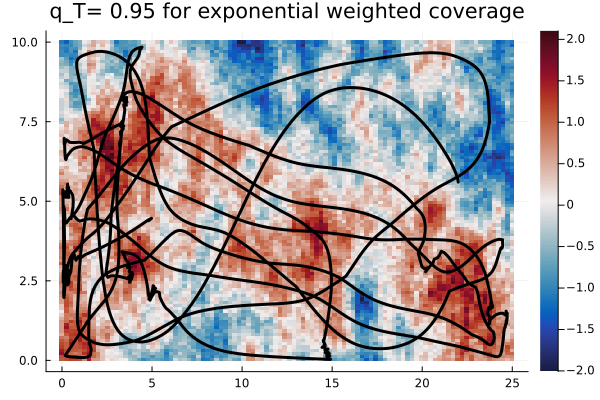

In [59]:
plot()
heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx)
for i=1:length(x0s)
    x = [r[i][1] for r in res_ergo_hp.xs]
    y = [r[i][2] for r in res_ergo_hp.xs]
    plot!(x,y, linewidth=3, color=:black, label = "")
end
plot!()

title!("q_T= 0.95 for exponential weighted coverage")

[ Info: Saved animation to /tmp/jl_mtMTYNSj43.gif


Plots.AnimatedGif("/tmp/jl_mtMTYNSj43.gif")
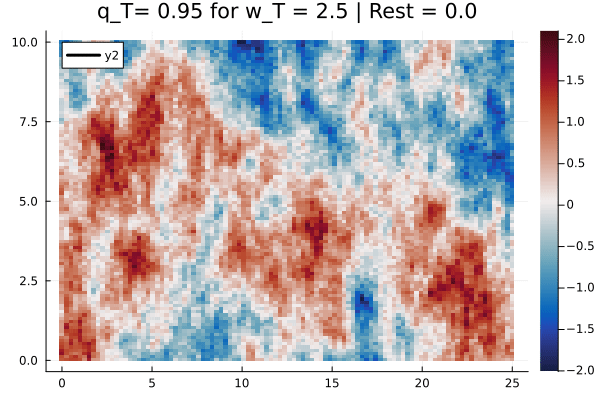

In [60]:
gr()
@gif for n = Int.(floor.(range(1, length(res_ergo_hp.xs), length=420)))
    plot()
    heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx)
    for i=1:length(x0s)
        x = [r[i][1] for r in res_ergo_hp.xs[1:n]]
        y = [r[i][2] for r in res_ergo_hp.xs[1:n]]
        plot!(x, y, linewidth=3, color=:black)
    end
    plot!()
    title!("q_T= 0.95 for w_T = 2.5 | Rest = 0.0")
end

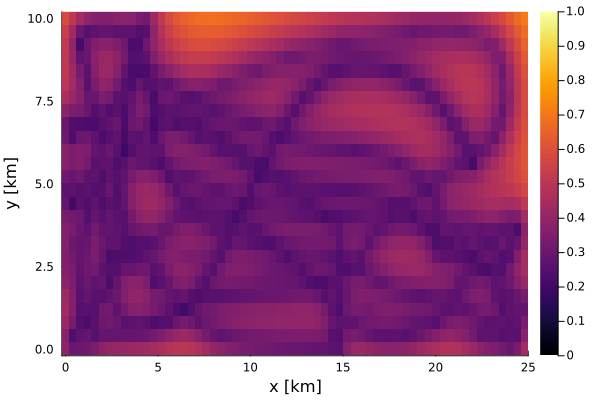

In [61]:
p2 = heatmap(ngpkf_grid, res_ergo_hp.w_hats[end], clims=(0, 1.0), plotstd=true)
# for i=1:length(x0s)
#     x = [r[i][1] for r in res_ergo.xs]
#     y = [r[i][2] for r in res_ergo.xs]
#     plot!(x, y, linewidth=3)
# end
plot!()

In [62]:
target_maps_exp = [res_ergo_hp.q_target_maps[1],]

for i=2:63:length(res_ergo_hp.q_target_maps)
    push!(target_maps_exp,res_ergo_hp.q_target_maps[i])
end

[ Info: Saved animation to /tmp/jl_qLkZOvEDsP.gif


Plots.AnimatedGif("/tmp/jl_qLkZOvEDsP.gif")
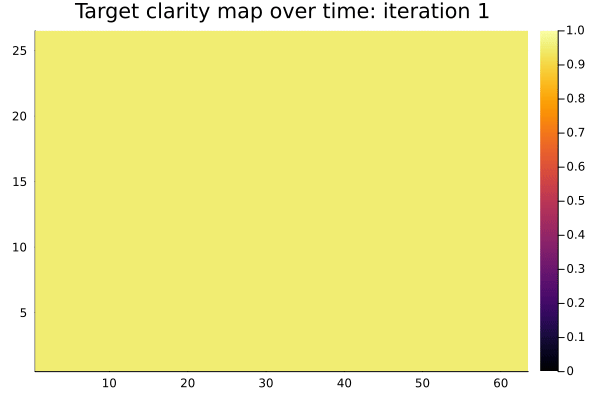

In [63]:
gr()
@gif for i=1:length(res_ergo_hp.q_target_maps)
    heatmap(res_ergo_hp.q_target_maps[i]', clims=(0, 1))
    title!("Target clarity map over time: iteration $i")
end

[ Info: Saved animation to /tmp/jl_y3iNk1eVwL.gif


Plots.AnimatedGif("/tmp/jl_y3iNk1eVwL.gif")
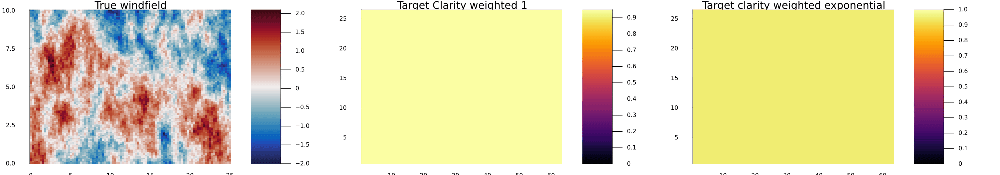

In [64]:
# Comparing two target clarities
gr()
@gif for i=1:length(res_ergo_hp.q_target_maps)
    p0 = heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx, title = "True windfield")
    p1 = heatmap(res_ergo_hp.q_target_maps[i]', title = "Target Clarity weighted 1")
    p2 = heatmap(res_ergo_hp.q_target_maps[i]', clims=(0, 1), title = "Target clarity weighted exponential")
    plot(p0, p1, p2, layout=@layout[a b c], size=(2000, 350))
#     title!("Weighted coverage")
end

[ Info: Saved animation to /tmp/jl_KhGlM3KXuF.gif


Plots.AnimatedGif("/tmp/jl_KhGlM3KXuF.gif")
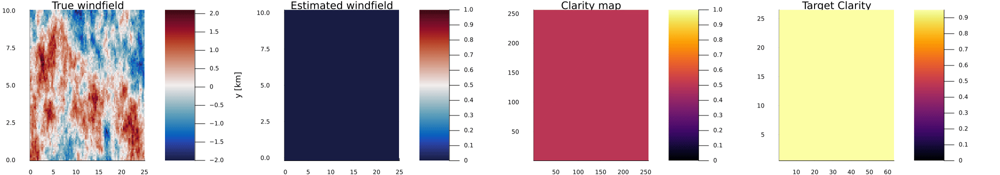

In [65]:
gr()
@gif for i=1:length(res_ergo_hp.ergo_q_maps)
    p0 = heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx, title = "True windfield")
    p1 = heatmap(ngpkf_grid, res_ergo_hp.w_hats[i],colormap=:balance, title = "Estimated windfield")
    p3 = heatmap(target_maps_exp[i]', title = "Target Clarity")
    p2 = heatmap(res_ergo_hp.ergo_q_maps[i]', clims=(0, 1), title = "Clarity map")
    plot(p0, p1, p2, p3, layout=@layout[a b c d], size=(2000, 350))
#     title!("Weighted coverage")
end

[ Info: Saved animation to /tmp/jl_IRgXYf2DmJ.gif


Plots.AnimatedGif("/tmp/jl_IRgXYf2DmJ.gif")
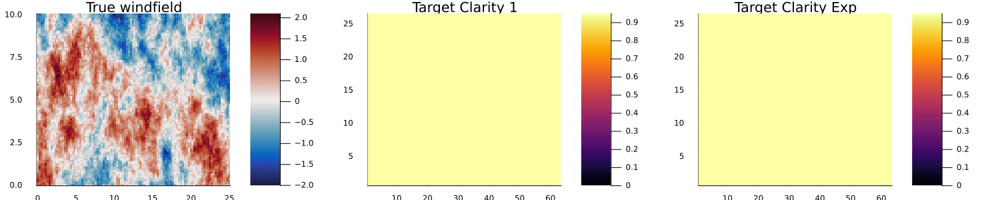

In [66]:
gr()
@gif for i=1:length(res_ergo_hp.ergo_q_maps)
    p0 = heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx, title = "True windfield")
    p1 = heatmap(target_maps_exp[i]', title = "Target Clarity 1")
    p2 = heatmap(target_maps_exp[i]', title = "Target Clarity Exp")
    plot(p0, p1, p2, layout=@layout[a b c], size=(1500, 300))
#     title!("Weighted coverage")
end

[ Info: Saved animation to /tmp/jl_QzqP6RGh2f.gif


Plots.AnimatedGif("/tmp/jl_QzqP6RGh2f.gif")
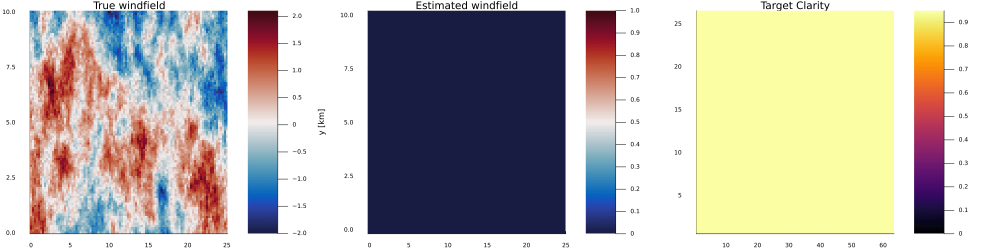

In [71]:
gr()
@gif for i=1:length(res_ergo_hp.ergo_q_maps)
    p0 = heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx, title = "True windfield")
    p1 = heatmap(ngpkf_grid, res_ergo_hp.w_hats[i],colormap=:balance, title = "Estimated windfield")
    p3 = heatmap(target_maps_exp[i]', title = "Target Clarity")
    plot(p0, p1, p3, layout=@layout[a b c], size=(2000, 500))
#     title!("Weighted coverage")
end

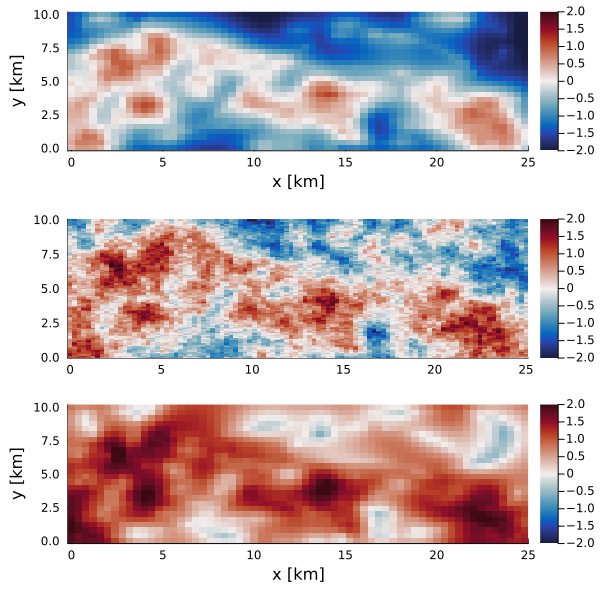

In [75]:
gr()

p1 = heatmap(ngpkf_grid, res_ergo_hp.w_hats[end],colormap=:balance, clims=(-2,2), plot_min=true)
p2 = heatmap(ngpkf_grid, res_ergo_hp.w_hats[end],colormap=:balance, clims=(-2,2), plot_max=true)
p3 = heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx, clims=(-2, 2))
    
plot(p1, p3, p2, layout = (@layout [a;b; c]), size=[600, 600])

In [76]:
# Compute RMSE

Nx, Ny = length(ngpkf_grid.xs), length(ngpkf_grid.ys)

M = reshape(KF.μ(res_ergo_hp.w_hats[end]), Nx, Ny)
heatmap(M',colormap=:balance, clims=(-2,2) )
x_new = 0:0.4:25
y_new = 0:0.4:10
Data_sampled = [env_data.itp_w(xi, yi) for yi in y_new, xi in x_new]
Diff = M' .- Data_sampled
rmse = sqrt(mean(Diff .^ 2))

0.268273785554004

In [77]:
M'

26×63 adjoint(::Matrix{Float64}) with eltype Float64:
  1.11096     1.15139     1.18413    …   0.85074    0.699635    0.585622
  1.16995     1.23065     1.28123        1.05736    0.79846     0.622912
  1.18097     1.24097     1.30989        1.13067    0.869247    0.6311
  1.14491     1.1446      1.1274         1.10914    0.800198    0.530764
  1.1009      1.01681     0.818087       1.07682    0.700257    0.445599
  1.09929     0.995278    0.7763     …   0.936864   0.618617    0.386692
  1.12716     1.0568      0.883527       0.683156   0.451769    0.273552
  1.12851     1.10625     0.897997       0.443801   0.254798    0.129428
  1.08143     1.1247      0.98201        0.334439   0.0765989  -0.00522659
  0.94042     0.991802    1.03563        0.314844   0.012988   -0.0941482
  ⋮                                  ⋱   ⋮                     
  0.216554    0.268624    0.419308      -0.965776  -0.917932   -0.861908
  0.104784    0.175229    0.33458       -1.01438   -0.978194   -0.916925
 -0.0

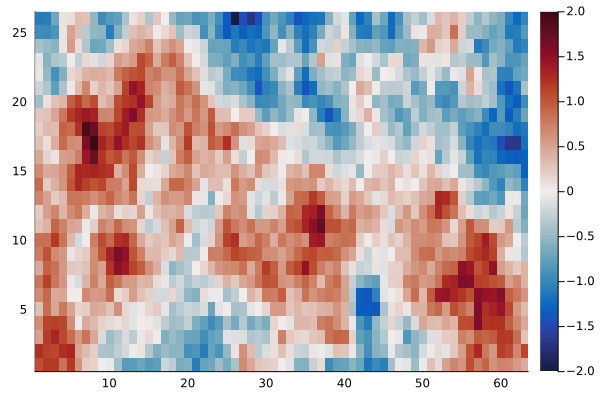

In [78]:
heatmap(Data_sampled,colormap=:balance, clims=(-2,2))

In [79]:
# Compute Precision

σ_prec = KF.σ(res_ergo_hp.w_hats[end])
M_prec = reshape(σ_prec, Nx, Ny)
precision = sum(M_prec)/length(M_prec)

0.34207309772219846

In [84]:
using LinearAlgebra, StatsBase

mean_deficit_1 = [mean(map( c -> max(0, 1.0 - c), q )) for q in res_ergo_hp.ergo_q_maps]
mean_deficit_1[end]

0.10483657474549024

In [85]:
ts = range(1, 100, 20)
time = collect(ts)

20-element Vector{Float64}:
   1.0
   6.2105263157894735
  11.421052631578947
  16.63157894736842
  21.842105263157894
  27.05263157894737
  32.26315789473684
  37.473684210526315
  42.68421052631579
  47.89473684210526
  53.10526315789474
  58.31578947368421
  63.526315789473685
  68.73684210526316
  73.94736842105263
  79.15789473684211
  84.36842105263158
  89.57894736842105
  94.78947368421052
 100.0

In [86]:
# plot(res_ergo.w_hat_ts, mean_deficit_1, marker=:dot)
gr()
plot()
plot!(time, mean_deficit_1, marker=:dot)
ylabel!("Clarity Deficit[0,1]")
xlabel!("Time [min]")
ylims!(0., 0.6)

In [89]:
h2 = 25 - 1
ux_min = 1 * h2

24

### Velocity Plots

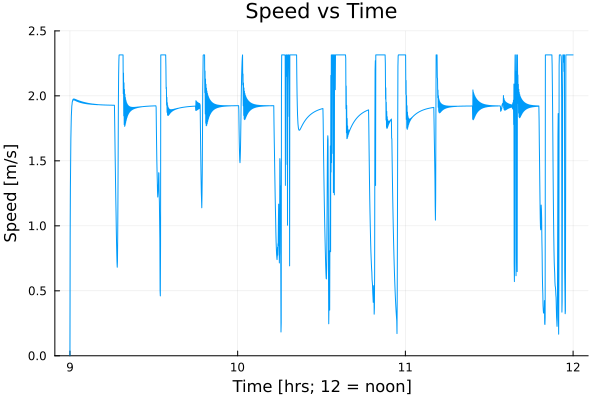

In [90]:
speed = norm.(res_ergo_hp.us)

plot(LinRange(T_begin, T_end, length(speed)), speed, legend=false)
ylims!(0., 2.5)
xlabel!("Time [hrs; 12 = noon]")
ylabel!("Speed [m/s]")
title!("Speed vs Time")